# Plotting a run with `PlotSink`

`PlotSink` is an output sink that draws a run's events as PNGs when it closes:

- each **scalar** name (`train/loss/total`, `eval/val/auroc`) becomes one line plot of
  its value against the training step;
- each **table** of named number columns becomes a curve, the first column on x and the
  others on y (a ROC curve: `{"fpr": [...], "tpr": [...]}`).

Any other plot is drawn with matplotlib and saved with `save_artifact`, which also
records it in the run's events.

Here a linear classifier learns which side of the line y = x a point lies on. The sink
plots its loss, its validation AUROC and its final ROC curve, and a custom plot shows
the boundary it learned.

Run from `examples/`. `lwfm` isn't an installed package yet, so put the repository root on the import path.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

## 1. The data

Points scattered around the line y = x. The label says whether a point lies above the
line, but the boundary is noisy near the line, so even the best linear classifier can't
reach an AUROC of 1.

In [2]:
import torch


def make_batches(count: int, batch_size: int = 64, seed: int = 0) -> list[dict]:
    """`count` batches of 2D points around y = x, labelled 1 above the line."""
    generator = torch.Generator().manual_seed(seed)
    batches = []
    for _ in range(count):
        x = torch.rand(batch_size, generator=generator) * 2 - 1  # in [-1, 1]
        y = x + 0.5 * torch.randn(batch_size, generator=generator)  # around y = x
        # Above the line, with a noisy boundary (std 0.3)
        noise = 0.3 * torch.randn(batch_size, generator=generator)
        label = (y > x + noise).long()
        batches.append(
            {
                "inputs": {"point": torch.stack([x, y], dim=1)},
                "targets": {"label": label},
            }
        )
    return batches


train_loader = make_batches(10)
val_loader = make_batches(5, seed=1)

## 2. A linear classifier

One `nn.Linear(2, 1)` gives a logit per point; the boundary it learns is a line. Binary
cross-entropy needs float targets and `BinaryAUROC` needs integer ones, so a two-line
loss module converts the label.

In [3]:
import torch.nn.functional as F
from torch import nn
from torchmetrics.classification import BinaryAUROC

from lwfm.core.graph import ExecutionGraph, ModelNode
from lwfm.core.losses import LossBinding, LossComposer
from lwfm.evaluation.metrics import MetricBinding
from lwfm.training import Trainer, seed_everything


class BinaryCrossEntropy(nn.Module):
    def forward(self, logit, label):
        return F.binary_cross_entropy_with_logits(logit, label.float())


seed_everything(0)
classifier = ModelNode(
    "classifier",
    nn.Sequential(nn.Linear(2, 1), nn.Flatten(0)),  # [B, 2] -> [B] logits
    inputs="inputs.point",
    outputs="logit",
)
graph = ExecutionGraph([classifier])
loss = LossComposer(
    [LossBinding("bce", BinaryCrossEntropy(), ["classifier.logit", "targets.label"])]
)
# BinaryAUROC applies the sigmoid itself when given logits
metrics = [MetricBinding("auroc", BinaryAUROC(), ["classifier.logit", "targets.label"])]

## 3. Training, with the plots as one more sink

`PlotSink` sits next to `LocalFileSink` in the router, so it sees every event: the
losses and learning rate the trainer logs, and the AUROC the `Evaluator` logs after
each epoch.

A ROC curve is a table, not one number, so the `Evaluator` can't produce it. After
training we compute it with torchmetrics' `BinaryROC` and write it as a `table` event,
still inside the `with`, so the sinks receive it before they close. The extra `chance`
column (equal to `fpr`) draws the diagonal of a random classifier.

`PlotSink` can't draw the learned boundary over the data, so that plot is drawn by hand
and saved with `save_artifact`: it writes the PNG, then sends an `artifact` event with
its path, so the run record lists it.

In [4]:
import json
import tempfile

from matplotlib.figure import Figure
from torchmetrics.classification import BinaryROC

from lwfm.results.artifacts import save_artifact
from lwfm.results.events import RunEvent
from lwfm.results.plots import PlotSink
from lwfm.results.router import OutputRouter
from lwfm.results.sinks import LocalFileSink

run_dir = Path(tempfile.mkdtemp()) / "roc_demo"

with OutputRouter(LocalFileSink(run_dir), PlotSink(run_dir / "plots")) as sink:
    result = Trainer(device="cpu", max_epochs=10, log_every_n_steps=5).fit(
        graph,
        train_loader,
        loss,
        torch.optim.SGD(classifier.parameters(), lr=0.5),
        val_loader=val_loader,
        metrics=metrics,
        output_sink=sink,
    )

    # Scores and labels for the whole validation set
    model = graph.deployable_model("classifier").eval()
    with torch.inference_mode():
        scores = torch.cat([model(batch["inputs"]["point"]) for batch in val_loader])
    labels = torch.cat([batch["targets"]["label"] for batch in val_loader])
    fpr, tpr, _ = BinaryROC()(scores, labels)
    roc = {"fpr": fpr.tolist(), "tpr": tpr.tolist(), "chance": fpr.tolist()}
    sink.write(RunEvent("table", "eval/val/roc", roc, step=result.global_step))

    # Custom plot: validation points and the learned line w_x * x + w_y * y + b = 0
    points = torch.cat([batch["inputs"]["point"] for batch in val_loader])
    (w_x, w_y), b = model[0].weight[0].tolist(), model[0].bias.item()
    figure = Figure(figsize=(4, 4), layout="constrained")
    axes = figure.subplots()
    axes.scatter(points[:, 0], points[:, 1], c=labels, cmap="coolwarm", s=8)
    axes.plot([-1, 1], [(w_x - b) / w_y, (-w_x - b) / w_y], "k", label="learned")
    axes.plot([-1, 1], [-1, 1], "k:", label="y = x")
    axes.set(title="plot/boundary", xlabel="x", ylabel="y", xlim=(-1, 1))
    axes.legend()
    save_artifact(
        run_dir,
        "plots/boundary.png",
        figure.savefig,  # any writer that takes a path
        sink,
        name="plot/boundary",
        step=result.global_step,
    )

print("final AUROC:", round(result.history[-1][1]["auroc"], 3))
print("learned weights (x, y):", classifier.module[0].weight.data.tolist())
print(sorted(path.name for path in (run_dir / "plots").iterdir()))
for line in (run_dir / "events.jsonl").open():  # only the custom plot is recorded
    event = json.loads(line)
    if event["kind"] == "artifact":
        print(event["name"], "->", event["value"])

final AUROC: 0.887
learned weights (x, y): [[-1.9303215742111206, 2.595590114593506]]
['boundary.png', 'eval_val_auroc.png', 'eval_val_roc.png', 'train_epoch_seconds.png', 'train_loss_bce.png', 'train_loss_total.png', 'train_lr.png']
plot/boundary -> plots/boundary.png


The weights have opposite signs and similar sizes, so the logit is roughly
proportional to y - x: the classifier has found the line y = x.

## 4. The plots

`PlotSink` saves one PNG per event name, `/` replaced by `_`; `boundary.png` is the
custom plot.

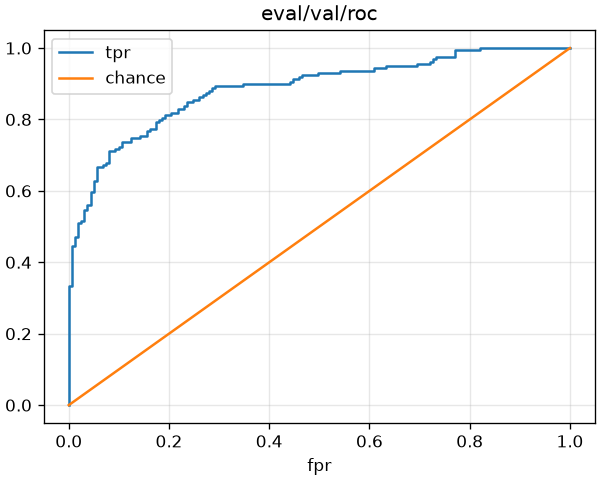

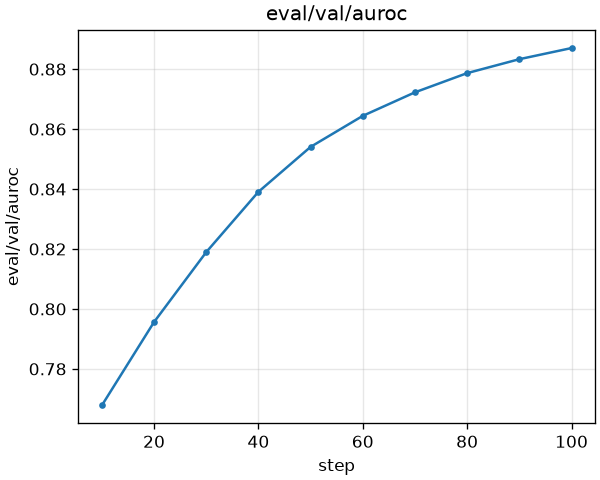

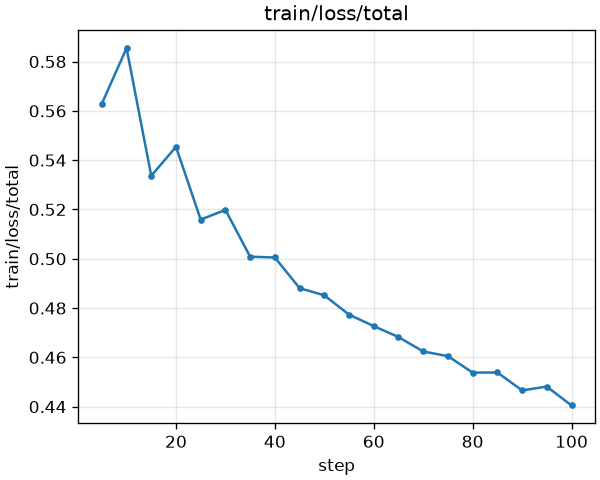

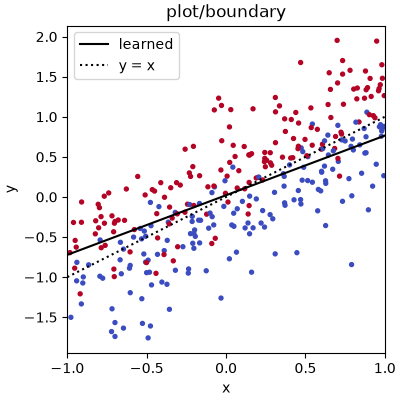

In [5]:
from IPython.display import Image, display

for name in ("eval_val_roc", "eval_val_auroc", "train_loss_total", "boundary"):
    display(Image(filename=run_dir / "plots" / f"{name}.png"))

## 5. Notes

- **What gets plotted.** Scalars need a step; a scalar logged without one (e.g. a final
  test score) has nothing to plot against and is skipped. Tables must be a dict of at
  least two equal-length numeric columns; other tables and messages (such as
  `trainer/settings`) are ignored.
- **Any other plot** goes through `save_artifact`, as `boundary.png` did. Its PNGs are
  listed in `events.jsonl` as `artifact` events; `PlotSink`'s are not, since a sink
  can't send events.
- **Plots are drawn on close**, so they cover the whole run. A crashed run still gets
  its plots: `OutputRouter` closes every sink on the way out.
- **The record is unchanged.** `LocalFileSink` still writes every event, the ROC table
  included, to the run directory, so the plots can be redrawn from it later.